# Eigenspace overlap: theoretical (KICL/HEA) vs empirical kernel eigenbasis

Figure-2-bottom-panel style check from *Predicting kernel regression learning curves from only raw
data statistics* (arXiv:2510.14878).

`run_eigendecomp_multidim.ipynb` compares the two **spectra**. This notebook compares the two
**eigenbases**: it bins both into shared logarithmic spectral bins, treats each bin as a
near-degenerate eigenspace, and plots the pairwise subspace overlap

$$\mathrm{Overlap}(i,j) = \frac{1}{d_j^{(\mathrm{emp})}}\left\|\Phi_i^{(\mathrm{th})\top}\Phi_j^{(\mathrm{emp})}\right\|_F^2$$

(Equation 44 of the paper). Concentration along the diagonal means theory and experiment agree.
Setup and `run_once` are copied from `run_eigendecomp_multidim.ipynb`, which is left untouched.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Mounted at /content/drive


In [ ]:
import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

Cloning into 'kernel_ICL'...
remote: Enumerating objects: 798, done.
remote: Counting objects: 100% (333/333), done.
remote: Compressing objects: 100% (232/232), done.
remote: Total 798 (delta 198), reused 231 (delta 96), pack-reused 465 (from 1)
Receiving objects: 100% (798/798), 55.73 MiB | 19.93 MiB/s, done.
Resolving deltas: 100% (392/392), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 16.11 MiB/s, done.
Resolving deltas: 100% (28/28), done.


In [ ]:
sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

In [ ]:
%matplotlib inline
import math
import os

import numpy as np
import torch
import matplotlib.pyplot as plt

from kernels_can_icl.kernel_theory_multidim import generate_multidim_kicl_monomials, compute_basis
from kernels_can_icl.kernel_eigsys import eigendecompose, kernel_matrix
from kernels_can_icl.task_distrs import RegressionTaskDistribution
from kernels_can_icl.level_coefficients import *
from kernels_can_icl.utils import estimate_max_n, seed_everything, ensure_torch, ensure_numpy
from kernels_can_icl.eigvec_overlap import (eigenspace_overlap, plot_eigenspace_overlap,
                                       summarize_overlap, compact_bins)

In [ ]:
KERNEL_WIDTH = 3
MAX_DEG = 3

config = {
    "seed": 42,
    "dim": 4,
    "L": 7,
    "distribution": "pretrain",
    "T": 1,
    "sigma_sq": 0.1,
    "draw_betas": "normal",
    "beta_sd": 1.0,
    "trials": 1,
    "kernel_class": "PolynomialKernel",#"LaplaceKernel",#"ReluNTK",
    "kernel_params": {
        "ridge": 0.01,
        "kernel_width": KERNEL_WIDTH,
        "max_degree": MAX_DEG,
        # "coeffs": [1.0 / (math.factorial(l) * KERNEL_WIDTH ** (2 * l)) for l in range(MAX_DEG+1)],
        # "coeffs": [1.1635035, 0.6293589, 0.1348020/2, 0.0173722/6], #ReLUNTK
        # "coeffs": [4.412876e-01, 5.993699e-02, (1.809221e-02)/2, (1.011731e-02)/6], #LAP
        "coeffs": [1.0, 0.111, 0.00617283951, 0.000228623685],
    },
    "n": 25600,
    "min_n": 2,
    "max_n": 30000,
    "memory_safety": 0.2,
    "matrix_factor": 3.0,
    "max_retries": 10,
    "retry_shrink": 0.96,
    "expt_dir": "kernel_ICL/validation",
    "base_name": "HEA_validation_T1_polynomial_eigspace",
}

In [ ]:
def pref_point_closed(betas, v, vq, e, L, d, w2):
    t = 1.0 / (2*w2)
    N2 = (betas**2).sum(1)                      # ‖β_τ‖², shape (T,)
    g  = 1 + 2*t*e + 2*t*v*N2/(1 + 2*t*v)
    return ((1+2*t*vq)**(-d/2) * (1+2*t*v)**(-d*(L-1)/2)
            * ensure_numpy(torch.mean(g**(-(L-1)/2))))

In [ ]:
def generate_data(task_distr: RegressionTaskDistribution, batch_sz):
    X_ctx, y_ctx, X_q, y_q = task_distr.generate_data(
        context_len=int(config["L"]), batch_sz=int(batch_sz),
        distribution=str(config["distribution"]), uniform_beta_sampling=True,
    )
    X = task_distr._get_input(X_ctx, y_ctx, X_q)
    y = y_q.squeeze(-1).squeeze(-1)
    return X, y


def run_once(n: int):
    """Same as run_eigendecomp_multidim.run_once, plus the inputs compute_basis needs.

    compute_basis wants the RAW natural-scale X_flat (not whitened), the betas and data_eigvals --
    none of which the original returned, since it only ever needed the spectra.
    """
    task_distr = RegressionTaskDistribution(
        dim=int(config["dim"]), num_weights=int(config["T"]),
        noise_variance=float(config["sigma_sq"]), sample_beta=str(config["draw_betas"]),
        sigma_beta2=float(config["beta_sd"]) ** 2, gram_wanted=False,
        context_len=int(config["L"]),
    )
    context_length = int(config["L"])
    dim = int(config["dim"])
    X_flat, y_vec = generate_data(task_distr, batch_sz=n)

    X_flat = ensure_torch(X_flat)
    y_vec = ensure_torch(y_vec)
    betas = task_distr.pretrain_W.detach()
    data_eigvals = (
        [task_distr.sigma_x2] * (context_length - 1) * dim
        + [dim * task_distr.sigma_x2 * task_distr.sigma_beta2 + float(config["sigma_sq"])] * (context_length - 1)
        + [task_distr.sigma_q2] * dim
    )

    w2 = config["kernel_params"]["kernel_width"] ** 2
    pref_kernel = pref_point_closed(
        betas=betas, v=task_distr.sigma_x2, vq=task_distr.sigma_q2,
        e=float(config["sigma_sq"]), L=(context_length - 1), d=dim, w2=w2) ** 2
    print(f"pref_kernel = {pref_kernel:.6e}")

    K = kernel_matrix(X_flat, config["kernel_class"], dict(config["kernel_params"]))
    emp_eigvals, emp_eigvecs = eigendecompose(K)
    del K                      # the N x N kernel is no longer needed; free it before compute_basis
    print("Empirical eigendecomposition done")

    level_coeffs = get_polynomial_coefficients(config["kernel_params"]["coeffs"])
    print("Generating theory eigenvalues")
    th_eigvals, monomials, impt_list, _degree_mass = generate_multidim_kicl_monomials(
        data_eigvals, num_monomials=int(1.04 * n), eval_level_coeff=level_coeffs,
        context_length=context_length, dim=dim, betas=betas,
        noise_var=float(config["sigma_sq"]), kmax=8,
    )

    return {
        "emp_eigvals": emp_eigvals,
        "emp_eigvecs": emp_eigvecs,
        "th_eigvals": th_eigvals,
        "monomials": monomials,
        "impt_list": impt_list,
        "pp": pref_kernel,
        # --- needed by compute_basis ---
        "X_flat": X_flat,
        "betas": betas,
        "data_eigvals": data_eigvals,
        "n": n,
    }

In [ ]:
# gen, rng = seed_everything(config["seed"], device_id=0)

n = estimate_max_n(config=config, n=config.get("n"))
retries = int(config["max_retries"])
shrink = float(config["retry_shrink"])
last_err = None

for _attempt in range(retries + 1):
    try:
        out = run_once(n=n)
        break
    except RuntimeError as err:
        last_err = err
        if not err:
            raise
        torch.cuda.empty_cache()
        print(f"{err} occurred, shrinking")
        n = max(int(n * shrink), int(config["min_n"]))
else:
    raise RuntimeError(f"Failed to eigendecompose after retries: {last_err}")

print(f"Done (n={n})")

pref_kernel = 8.271272e-01
Empirical eigendecomposition done
Generating theory eigenvalues
Done (n=25600)


## Theoretical eigenfunctions

`compute_basis` returns the eigenfunction whose eigenvalue is the matching entry of
`generate_multidim_kicl_monomials`, evaluated on the sample, with unit-L2-norm columns — the same
normalization `eigendecompose` returns the empirical eigenvectors in, so the two are directly
comparable.

Two things are capped here:

* **`N_MODES`** — `run_once` asks for `1.2 * n` monomials. Building eigenfunctions for all of them
  at `n = 25600` would be a 25600×30720 float64 matrix (~6.3 GB) on top of `emp_eigvecs`. The
  overlap plot only needs the head of the spectrum; the paper itself notes that tail discrepancies
  come from finite-size distortion of the *empirical* basis rather than from the theory.
* **zero eigenvalues** — `get_polynomial_coefficient` returns 0 above `len(coeffs) - 1`, so every
  monomial of degree > 3 here has eigenvalue exactly 0. Those cannot be placed on a log axis, and
  building their eigenfunctions would be wasted work, so they are dropped first.

In [ ]:
N_MODES = config["n"]

NBINS   = 20       # logarithmic spectral bins along each axis -- see the sweep below

th_eigvals_all = np.asarray(ensure_numpy(out["th_eigvals"]), dtype=np.float64)

# Drop zero-eigenvalue modes (degree > len(coeffs)-1), then take the top N_MODES.
keep = np.where(th_eigvals_all > 0)[0][:N_MODES]
th_monos = [out["monomials"][i] for i in keep]
th_vals  = th_eigvals_all[keep] * out["pp"]        # same scale convention as the eigenvalue plots

degs = np.array([sum(m.values()) for m in th_monos])
print(f"kept {len(keep)} of {len(th_eigvals_all)} theory modes "
      f"(degree histogram: { {int(d): int((degs == d).sum()) for d in np.unique(degs)} })")

th_eigvecs = compute_basis(
    out["X_flat"], th_monos,
    context_length=int(config["L"]), dim=int(config["dim"]),
    betas=out["betas"], noise_var=float(config["sigma_sq"]),
    data_eigvals=out["data_eigvals"],
)
norms = np.linalg.norm(th_eigvecs, axis=0)
print(f"th_eigvecs {th_eigvecs.shape}; column norms "
      f"min={norms.min():.4f} max={norms.max():.4f} mean={norms.mean():.4f}  (1.0 is ideal)")

kept 7770 of 26624 theory modes (degree histogram: {0: 1, 1: 34, 2: 595, 3: 7140})
th_eigvecs (25600, 7770); column norms min=0.1879 max=1.0630 mean=0.9972  (1.0 is ideal)


## Eigenspace overlap (Equation 44)

Both spectra must be on the **same scale** before binning — `emp_eigvals / n` against
`th_eigvals * pp`, matching what the eigenvalue plots in `run_eigendecomp_multidim.ipynb` use.
Binning two differently-scaled spectra shears the heatmap off the diagonal, which looks exactly
like a theory failure.

`orthonormalize=True` QRs the theoretical columns within each bin first. Equation 44 treats
`Φ_i` as an eigenspace *basis*, which presumes orthonormal columns; ours are only approximately
orthonormal on a finite sample, and QR preserves the span so the result is the true subspace
overlap rather than a double-count.

In [ ]:
def merge_one_sided(edges, th, emp):
    """Drop interior edges until every bin holds modes from BOTH spectra -> zero grey."""
    edges = np.asarray(edges, float).copy()
    while len(edges) > 2:
        ct, _ = np.histogram(th,  bins=edges)
        ce, _ = np.histogram(emp, bins=edges)
        bad = np.where((ct == 0) | (ce == 0))[0]
        if bad.size == 0:
            break
        i = int(bad[0])
        edges = np.delete(edges, i + 1 if i + 1 < len(edges) - 1 else i)
    return edges

In [ ]:
import math, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt

def gap_edges(th, emp, min_ratio=1.02):
    """Bin edges in the multiplicative GAPS of the pooled spectrum -> one bin per plateau."""
    pooled = np.sort(np.concatenate([np.asarray(th, float), np.asarray(emp, float)]))[::-1]
    pooled = pooled[pooled > 0]
    if len(pooled) < 2:
        return np.array([pooled.min() * .999, pooled.max() * 1.001])
    cuts = [math.sqrt(a * b) for a, b in zip(pooled[:-1], pooled[1:]) if a / b > min_ratio]
    return np.concatenate([[pooled.min() * .999], np.unique(cuts), [pooled.max() * 1.001]])

def merge_one_sided(edges, th, emp):
    """Drop interior edges until every bin holds modes from BOTH spectra -> zero grey cells."""
    edges = np.asarray(edges, float).copy()
    while len(edges) > 2:
        ct, _ = np.histogram(th, bins=edges); ce, _ = np.histogram(emp, bins=edges)
        bad = np.where((ct == 0) | (ce == 0))[0]
        if bad.size == 0: break
        i = int(bad[0])
        edges = np.delete(edges, i + 1 if i + 1 < len(edges) - 1 else i)
    return edges

def build_edges(th, emp, lam_floor, split, min_ratio_head=1.02, n_coarse=2):
    """Fine bins above `split`, `n_coarse` wide bins below. Canvas share == BIN share."""
    th = np.asarray(th, float); emp = np.asarray(emp, float)
    tv, ev = th[th >= lam_floor], emp[emp >= lam_floor]
    fine = gap_edges(tv[tv >= split], ev[ev >= split], min_ratio_head)
    fine[0] = split
    coarse = np.geomspace(min(tv.min(), ev.min()) * 0.999, split, n_coarse + 1)
    return merge_one_sided(np.concatenate([coarse[:-1], fine]), tv, ev)

def plot_overlap(res, edges, title="", outpath=None, max_ticks=8):
    """Diagonal runs top-left (large lambda) -> bottom-right (small), matching the eigval plots."""
    M = res["overlap"] if isinstance(res, dict) else np.asarray(res, float)
    edges = np.asarray(edges, float)
    if M.shape[0] != len(edges) - 1:
        raise ValueError("edges must match the overlap grid; don't compact")
    D = M[::-1, ::-1]                                   # eigenspace_overlap bins ASCEND in lambda
    centers = np.sqrt(edges[:-1] * edges[1:])[::-1]
    cm = mpl.colormaps.get_cmap("magma").copy(); cm.set_bad(color="#333333")
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    im = ax.imshow(np.ma.masked_invalid(D), cmap=cm, vmin=0, vmax=1,
                   origin="upper", interpolation="nearest", aspect="equal")
    nb = D.shape[0]; idx = np.arange(0, nb, max(1, nb // max_ticks))
    ax.set_xticks(idx); ax.set_yticks(idx)
    ax.set_xticklabels([f"{centers[i]:.0e}" for i in idx], rotation=45, fontsize=7)
    ax.set_yticklabels([f"{centers[i]:.0e}" for i in idx], fontsize=7)
    ax.xaxis.set_ticks_position("bottom")
    ax.set_xlabel("Empirical eigenspace"); ax.set_ylabel("Predicted eigenspace")
    ax.set_title(title, fontsize=10)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("overlap", fontsize=9); cb.ax.set_yticks([0., .5, 1.])
    fig.tight_layout()
    if outpath: fig.savefig(outpath, dpi=200, bbox_inches="tight")
    return ax

14 bins, 12 above 1e-05
bins: 14 total, 14 populated on both sides (14 predicted, 14 empirical)
modes binned: 3710 predicted, 3901 empirical
diagonal overlap on populated bins: mean=0.324 min=0.000 max=0.993
diagonal over the top 10 populated bins: 0.14 0.00 0.00 0.99 0.00 0.00 0.03 0.01 0.00 0.92
column sums (1.0 = predicted basis complete): min=0.748 median=1.162 max=1.242
  ^^ sums above 1 mean the predicted eigenspaces are not orthogonal ACROSS bins, so some empirical directions are claimed twice (1.24 = up to 24% over-count). Within a bin QR handles it; across bins it is a property of the predicted basis.
  ^^ sums below 1 are truncation, not error: the predicted basis was cut off at a finite mode budget, so it cannot fully span those empirical eigenspaces.
worst predicted-bin conditioning min|R_ii|/max|R_ii| = 1.83e-01 (bin 1, d_th=543); small values mean near-dependent predicted columns in that bin
SCALE: median lambda_th/lambda_emp at matched index = 0.960; median bin offset of

<Axes: title={'center': 'PolynomialKernel eigenvector overlap @ linreg ICL, T=1, d=4, L=7, n=25600'}, xlabel='Empirical eigenspace', ylabel='Predicted eigenspace'>

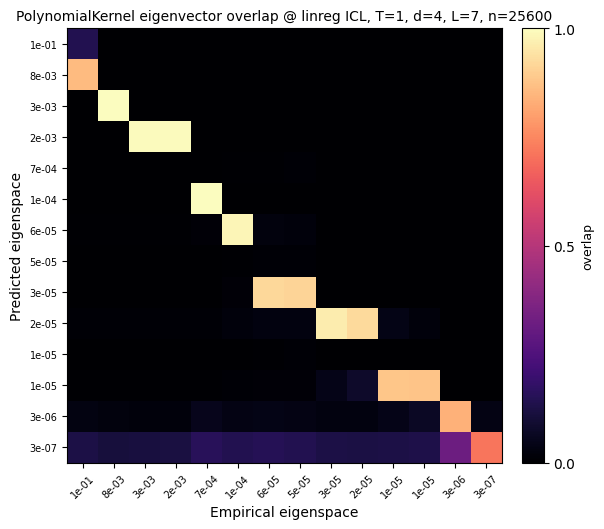

In [ ]:
LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE = 1e-7, 1e-5, 1.01, 2

n_emp = min(N_MODES, out["emp_eigvecs"].shape[1])
emp_vals = ensure_numpy(out["emp_eigvals"][:n_emp]) / out["n"]
emp_vecs = ensure_numpy(out["emp_eigvecs"][:, :n_emp])

kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
edges = build_edges(th_vals, emp_vals, LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE)
print(f"{len(edges)-1} bins, {int((edges[:-1] >= SPLIT).sum())} above {SPLIT:.0e}")

res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
                         emp_vecs[:, ke],   emp_vals[ke],
                         bin_edges=edges, orthonormalize=True)
print(summarize_overlap(res))

plot_overlap(res, edges, title=f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
                               f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

In [ ]:
folder_path = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"
file_path = os.path.join(folder_path, f"overlap_{config['base_name']}.pkl")
savedict = {
    "config": config,
    "N_MODES": N_MODES,
    "NBINS": NBINS,
    "results": {
        "emp_eigs": ensure_numpy(out["emp_eigvals"]),
        "th_eigs": ensure_numpy(out["th_eigvals"]),
        "pp": out["pp"],
        "overlap": res["overlap"],
        "bin_edges": res["bin_edges"],
        "d_th": res["d_th"],
        "d_emp": res["d_emp"],
        "col_sums": res["col_sums"],
        "cond": res["cond"],
    },
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, "wb") as f:
    pickle.dump(savedict, f)
print(f"saved -> {file_path}")

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/overlap_HEA_validation_T1_polynomial_eigspace.pkl


12 bins, 10 above 8e-05
bins: 12 total, 12 populated on both sides (12 predicted, 12 empirical)
modes binned: 2271 predicted, 11629 empirical
diagonal overlap on populated bins: mean=0.276 min=0.000 max=0.971
diagonal over the top 10 populated bins: 0.10 0.00 0.97 0.72 0.03 0.05 0.86 0.01 0.46 0.00
column sums (1.0 = predicted basis complete): min=0.121 median=1.007 max=1.113
  ^^ sums above 1 mean the predicted eigenspaces are not orthogonal ACROSS bins, so some empirical directions are claimed twice (1.11 = up to 11% over-count). Within a bin QR handles it; across bins it is a property of the predicted basis.
  ^^ sums below 1 are truncation, not error: the predicted basis was cut off at a finite mode budget, so it cannot fully span those empirical eigenspaces.
worst predicted-bin conditioning min|R_ii|/max|R_ii| = 7.02e-01 (bin 3, d_th=332); small values mean near-dependent predicted columns in that bin
SCALE: median lambda_th/lambda_emp at matched index = 0.488; median bin offset o

<Axes: title={'center': 'LaplaceKernel eigenvector overlap @ linreg ICL, T=256, d=4, L=10, n=25600'}, xlabel='Empirical eigenspace', ylabel='Predicted eigenspace'>

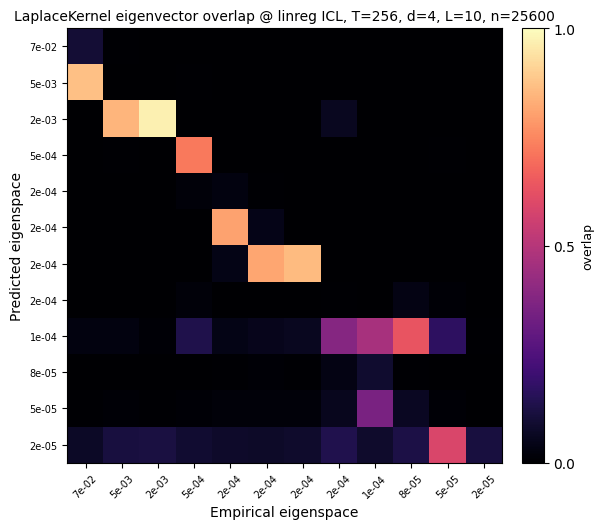

In [ ]:
LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE = 1e-5, 8e-5, 1.01, 2

n_emp = min(N_MODES, out["emp_eigvecs"].shape[1])
emp_vals = ensure_numpy(out["emp_eigvals"][:n_emp]) / out["n"]
emp_vecs = ensure_numpy(out["emp_eigvecs"][:, :n_emp])

kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
edges = build_edges(th_vals, emp_vals, LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE)
print(f"{len(edges)-1} bins, {int((edges[:-1] >= SPLIT).sum())} above {SPLIT:.0e}")

res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
                         emp_vecs[:, ke],   emp_vals[ke],
                         bin_edges=edges, orthonormalize=True)
print(summarize_overlap(res))

plot_overlap(res, edges, title=f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
                               f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

In [ ]:
folder_path = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"
file_path = os.path.join(folder_path, f"overlap_{config['base_name']}.pkl")
savedict = {
    "config": config,
    "N_MODES": N_MODES,
    "NBINS": NBINS,
    "results": {
        "emp_eigs": ensure_numpy(out["emp_eigvals"]),
        "th_eigs": ensure_numpy(out["th_eigvals"]),
        "pp": out["pp"],
        "overlap": res["overlap"],
        "bin_edges": res["bin_edges"],
        "d_th": res["d_th"],
        "d_emp": res["d_emp"],
        "col_sums": res["col_sums"],
        "cond": res["cond"],
    },
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, "wb") as f:
    pickle.dump(savedict, f)
print(f"saved -> {file_path}")

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/overlap_HEA_validation_T256_laplace_eigspace.pkl


17 bins, 15 above 7e-05
bins: 17 total, 17 populated on both sides (17 predicted, 17 empirical)
modes binned: 2280 predicted, 23285 empirical
diagonal overlap on populated bins: mean=0.387 min=0.000 max=0.970
diagonal over the top 10 populated bins: 0.14 0.00 0.00 0.94 0.97 0.95 0.93 0.86 0.00 0.03
column sums (1.0 = predicted basis complete): min=0.027 median=1.062 max=1.155
  ^^ sums above 1 mean the predicted eigenspaces are not orthogonal ACROSS bins, so some empirical directions are claimed twice (1.16 = up to 16% over-count). Within a bin QR handles it; across bins it is a property of the predicted basis.
  ^^ sums below 1 are truncation, not error: the predicted basis was cut off at a finite mode budget, so it cannot fully span those empirical eigenspaces.
worst predicted-bin conditioning min|R_ii|/max|R_ii| = 8.67e-01 (bin 6, d_th=12); small values mean near-dependent predicted columns in that bin
SCALE: median lambda_th/lambda_emp at matched index = 0.583; median bin offset of

<Axes: title={'center': 'ReluNTK eigenvector overlap @ linreg ICL, T=4, d=4, L=7, n=25600'}, xlabel='Empirical eigenspace', ylabel='Predicted eigenspace'>

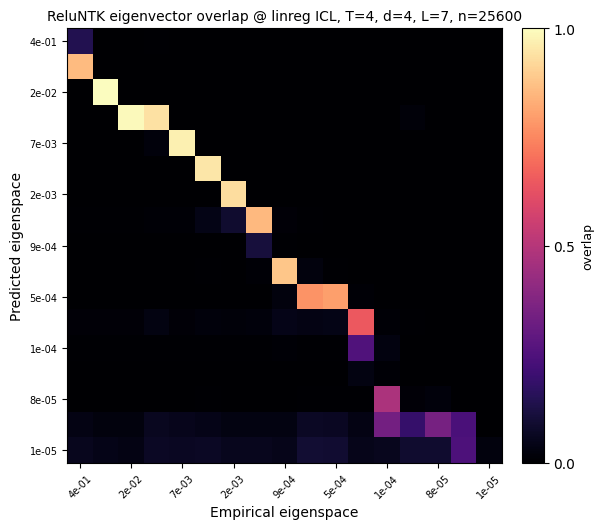

In [ ]:
LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE = 6e-6, 7e-5, 1.018, 2

n_emp = min(N_MODES, out["emp_eigvecs"].shape[1])
emp_vals = ensure_numpy(out["emp_eigvals"][:n_emp]) / out["n"]
emp_vecs = ensure_numpy(out["emp_eigvecs"][:, :n_emp])

kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
edges = build_edges(th_vals, emp_vals, LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE)
print(f"{len(edges)-1} bins, {int((edges[:-1] >= SPLIT).sum())} above {SPLIT:.0e}")

res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
                         emp_vecs[:, ke],   emp_vals[ke],
                         bin_edges=edges, orthonormalize=True)
print(summarize_overlap(res))

plot_overlap(res, edges, title=f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
                               f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

In [ ]:
folder_path = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"
file_path = os.path.join(folder_path, f"overlap_{config['base_name']}.pkl")
savedict = {
    "config": config,
    "N_MODES": N_MODES,
    "NBINS": NBINS,
    "results": {
        "emp_eigs": ensure_numpy(out["emp_eigvals"]),
        "th_eigs": ensure_numpy(out["th_eigvals"]),
        "pp": out["pp"],
        "overlap": res["overlap"],
        "bin_edges": res["bin_edges"],
        "d_th": res["d_th"],
        "d_emp": res["d_emp"],
        "col_sums": res["col_sums"],
        "cond": res["cond"],
    },
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, "wb") as f:
    pickle.dump(savedict, f)
print(f"saved -> {file_path}")

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/overlap_HEA_validation_T4_reluntk_eigspace.pkl


15 bins, 13 above 1e-04
bins: 15 total, 15 populated on both sides (15 predicted, 15 empirical)
modes binned: 1328 predicted, 1533 empirical
diagonal overlap on populated bins: mean=0.497 min=0.001 max=0.992
diagonal over the top 10 populated bins: 0.99 0.98 0.96 0.48 0.95 0.97 0.00 0.01 0.00 0.04
column sums (1.0 = predicted basis complete): min=0.659 median=1.141 max=1.224
  ^^ sums above 1 mean the predicted eigenspaces are not orthogonal ACROSS bins, so some empirical directions are claimed twice (1.22 = up to 22% over-count). Within a bin QR handles it; across bins it is a property of the predicted basis.
  ^^ sums below 1 are truncation, not error: the predicted basis was cut off at a finite mode budget, so it cannot fully span those empirical eigenspaces.
worst predicted-bin conditioning min|R_ii|/max|R_ii| = 7.84e-01 (bin 1, d_th=549); small values mean near-dependent predicted columns in that bin
SCALE: median lambda_th/lambda_emp at matched index = 1.272; median bin offset of

<Axes: title={'center': 'GaussianKernel eigenvector overlap @ linreg ICL, T=16, d=4, L=7, n=20037'}, xlabel='Empirical eigenspace', ylabel='Predicted eigenspace'>

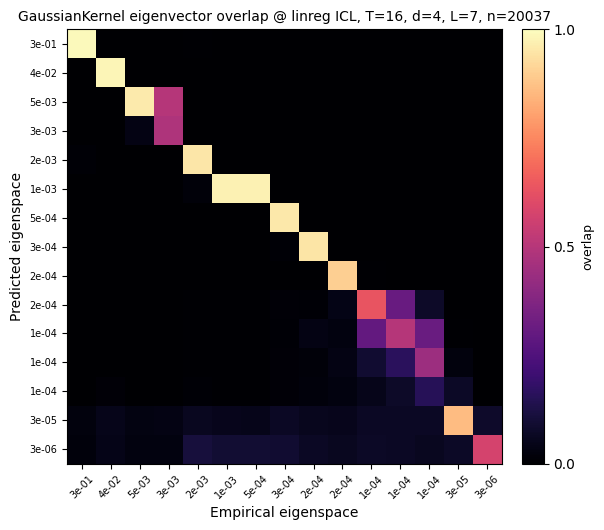

In [ ]:
LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE = 1e-6, 1e-4, 1.008, 2

n_emp = min(N_MODES, out["emp_eigvecs"].shape[1])
emp_vals = ensure_numpy(out["emp_eigvals"][:n_emp]) / out["n"]
emp_vecs = ensure_numpy(out["emp_eigvecs"][:, :n_emp])

kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
edges = build_edges(th_vals, emp_vals, LAM_FLOOR, SPLIT, MR_HEAD, N_COARSE)
print(f"{len(edges)-1} bins, {int((edges[:-1] >= SPLIT).sum())} above {SPLIT:.0e}")

res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
                         emp_vecs[:, ke],   emp_vals[ke],
                         bin_edges=edges, orthonormalize=True)
print(summarize_overlap(res))

plot_overlap(res, edges, title=f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
                               f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

In [ ]:
folder_path = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"
file_path = os.path.join(folder_path, f"overlap_{config['base_name']}.pkl")
savedict = {
    "config": config,
    "N_MODES": N_MODES,
    "NBINS": NBINS,
    "results": {
        "emp_eigs": ensure_numpy(out["emp_eigvals"]),
        "th_eigs": ensure_numpy(out["th_eigvals"]),
        "pp": out["pp"],
        "overlap": res["overlap"],
        "bin_edges": res["bin_edges"],
        "d_th": res["d_th"],
        "d_emp": res["d_emp"],
        "col_sums": res["col_sums"],
        "cond": res["cond"],
    },
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, "wb") as f:
    pickle.dump(savedict, f)
print(f"saved -> {file_path}")

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/overlap_HEA_validation_T16_gaussian_eigspace.pkl


In [ ]:
def gap_edges(th, emp, min_ratio=1.04):
    pooled = np.sort(np.concatenate([np.asarray(th), np.asarray(emp)]))[::-1]
    pooled = pooled[pooled > 0]
    cuts = [np.sqrt(a * b) for a, b in zip(pooled[:-1], pooled[1:]) if a / b > min_ratio]
    return np.concatenate([[pooled.min() * 0.999], np.unique(cuts), [pooled.max() * 1.001]])

n_emp = min(N_MODES, out["emp_eigvecs"].shape[1])
emp_vals = ensure_numpy(out["emp_eigvals"][:n_emp]) / out["n"]
emp_vecs = ensure_numpy(out["emp_eigvecs"][:, :n_emp])

out["emp_eigvecs"] = None            # free the full n x n matrix (2.6 GB at n=25600)
import gc; gc.collect()

LAM_FLOOR = th_vals.min()            # keep every theory mode; crop only the empirical tail
MIN_RATIO = 1.04                     # -> ~19 bins


kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
edges = gap_edges(th_vals[kt], emp_vals[ke], MIN_RATIO)
edges = merge_one_sided(edges, th_vals[kt], emp_vals[ke])      # <-- the fix
print(f"{len(edges)-1} bins, zero grey")

res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
                         emp_vecs[:, ke],   emp_vals[ke],
                         bin_edges=edges, orthonormalize=True)

# kt, ke = th_vals >= LAM_FLOOR, emp_vals >= LAM_FLOOR
# edges = gap_edges(th_vals[kt], emp_vals[ke], MIN_RATIO)
# print(f"{len(edges)-1} bins; theory {kt.sum()}, empirical {ke.sum()} modes")

# res = eigenspace_overlap(th_eigvecs[:, kt], th_vals[kt],
#                          emp_vecs[:, ke],   emp_vals[ke],
#                          bin_edges=edges, orthonormalize=True)
print(summarize_overlap(res))

# Bin-count sweep. This ICL spectrum is a coarse STAIRCASE (a few highly degenerate plateaus), not
# the dense spectrum the paper's nbins=40 was tuned for, so narrow log bins split a single plateau
# across a boundary and the diagonal drops for reasons that have nothing to do with the theory.
# Measured at d=4, L=7, n=4000, degree<=2: mean diagonal 0.56 (40 bins) -> 0.91 (12 bins).
print()
print("nbins sweep (mean diagonal over bins populated on both sides):")
for nb in (40, 30, 20, 15, 12, 10):
    r = eigenspace_overlap(th_eigvecs, th_vals, emp_vecs, emp_vals, nbins=nb, orthonormalize=True)
    M, both = r["overlap"], (r["d_th"] > 0) & (r["d_emp"] > 0)
    dg = np.array([M[i, i] for i in range(nb)])
    match = int((r["d_th"][both] == r["d_emp"][both]).sum())
    print(f"  nbins={nb:>3}  mean diag={np.nanmean(dg[both]):.3f}  "
          f"populated={int(both.sum()):>2}  bins where d_th==d_emp: {match}/{int(both.sum())}")

47 bins, zero grey
bins: 47 total, 47 populated on both sides (47 predicted, 47 empirical)
modes binned: 1306 predicted, 1332 empirical
diagonal overlap on populated bins: mean=0.232 min=0.000 max=0.996
diagonal over the top 10 populated bins: 1.00 0.99 0.93 0.24 0.95 0.98 0.00 0.01 0.00 0.01
column sums (1.0 = predicted basis complete): min=0.200 median=1.125 max=1.710
  ^^ sums above 1 mean the predicted eigenspaces are not orthogonal ACROSS bins, so some empirical directions are claimed twice (1.71 = up to 71% over-count). Within a bin QR handles it; across bins it is a property of the predicted basis.
  ^^ sums below 1 are truncation, not error: the predicted basis was cut off at a finite mode budget, so it cannot fully span those empirical eigenspaces.
worst predicted-bin conditioning min|R_ii|/max|R_ii| = 8.31e-01 (bin 27, d_th=6); small values mean near-dependent predicted columns in that bin
SCALE: median lambda_th/lambda_emp at matched index = 1.218; median bin offset of the b

bins 47 -> 47; grey 0/2209 (0%) -> 0/2209 (0%)


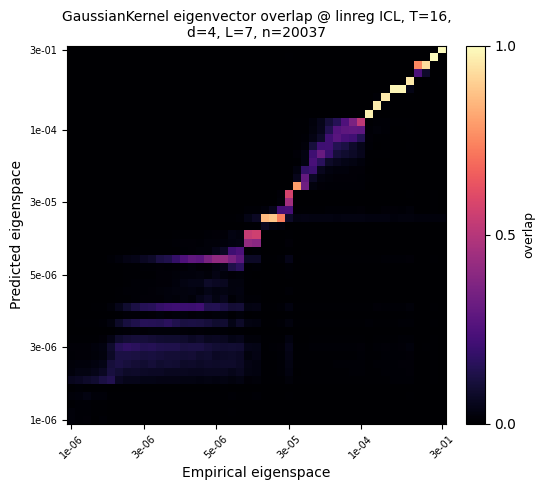

In [ ]:
title = (f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
         f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

c = compact_bins(res)
g0, g1 = np.isnan(res["overlap"]), np.isnan(c["overlap"])
print(f"bins {res['overlap'].shape[0]} -> {c['overlap'].shape[0]}; "
      f"grey {g0.sum()}/{g0.size} ({100*g0.mean():.0f}%) -> "
      f"{g1.sum()}/{g1.size} ({100*g1.mean():.0f}%)")

plot_eigenspace_overlap(res, title=title, show_axis_values=True)
plt.show()

bins 22 -> 22; grey 244/484 (50%) -> 244/484 (50%)


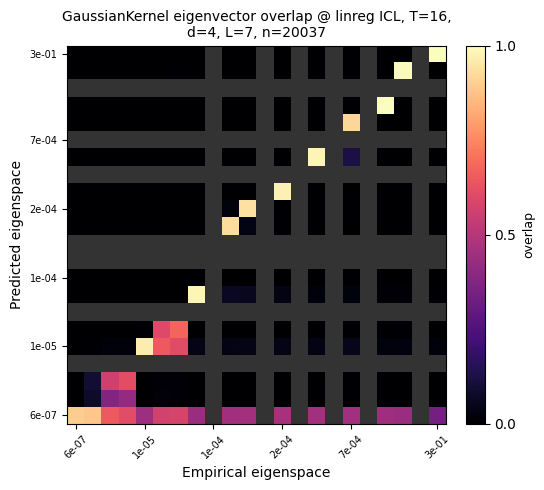

In [ ]:
title = (f"{config['kernel_class']} eigenvector overlap @ linreg ICL, "
         f"T={config['T']}, d={config['dim']}, L={config['L']}, n={out['n']}")

c = compact_bins(res)
g0, g1 = np.isnan(res["overlap"]), np.isnan(c["overlap"])
print(f"bins {res['overlap'].shape[0]} -> {c['overlap'].shape[0]}; "
      f"grey {g0.sum()}/{g0.size} ({100*g0.mean():.0f}%) -> "
      f"{g1.sum()}/{g1.size} ({100*g1.mean():.0f}%)")

plot_eigenspace_overlap(res, title=title, show_axis_values=True)
plt.show()

### Reading the figure

Rows are predicted eigenspaces, columns empirical, both increasing in eigenvalue up and to the
right. Bright on the diagonal = the HEA predicts that eigenspace.

Bins with no modes on *either* side are dropped (`drop_empty=True`), since on this staircase
spectrum they are most of the grid and bury the diagonal — at nbins=20 that takes the figure from
75% grey to 31%, and the diagonal is unaffected because rows and columns lose the same bins. The
axis ticks are eigenvalues, so the bins are no longer evenly spaced. Pass `drop_empty=False` for
the literal full log-uniform grid.

Grey that remains is a bin populated on exactly one side — "theory puts modes here, experiment
puts none", or the reverse. That is a real disagreement, so it stays visible.

Two known effects worth separating from a genuine theory failure:

* **Column sums below 1** are truncation, not error — the predicted basis is cut off at `N_MODES`,
  so it cannot fully span an empirical eigenspace whose partners lie outside the budget. Worst near
  the low-eigenvalue edge.
* **A weak diagonal in the middle bins** is usually bin straddling, not theory error. This
  spectrum is a staircase of highly degenerate plateaus; when one plateau falls either side of a
  bin edge, theory and empirical land in adjacent bins and the diagonal cell goes dark. The sweep
  printed above is the check — if the diagonal improves as bins widen, it was straddling.
* **Column sums above 1** mean the predicted eigenspaces are not orthogonal *across* bins, so two
  of them claim the same empirical direction. QR fixes this within a bin but cannot across bins.
* **Off-diagonal mass in the mid/low bins** is partly the degree≥3 cross-family overlap in the
  eigenvalue engine: `get_cached_general_roots` diagonalizes each integer-partition family
  separately and orthogonalizes only against *lower-degree* functions, so same-degree
  different-family eigenfunctions genuinely overlap (~0.33 for (3,) vs (2,1) at degree 3). That is a
  property of the theory being tested, not of this plot.

A broken diagonal in the **head** of the spectrum is a real disagreement and worth chasing.

In [ ]:
folder_path = "/content/drive/My Drive/picl/results/kernels/eigenstructure/"
file_path = os.path.join(folder_path, f"overlap_{config['base_name']}.pkl")
savedict = {
    "config": config,
    "N_MODES": N_MODES,
    "NBINS": NBINS,
    "results": {
        "emp_eigs": ensure_numpy(out["emp_eigvals"]),
        "th_eigs": ensure_numpy(out["th_eigvals"]),
        "pp": out["pp"],
        "overlap": res["overlap"],
        "bin_edges": res["bin_edges"],
        "d_th": res["d_th"],
        "d_emp": res["d_emp"],
        "col_sums": res["col_sums"],
        "cond": res["cond"],
    },
}
os.makedirs(folder_path, exist_ok=True)
with open(file_path, "wb") as f:
    pickle.dump(savedict, f)
print(f"saved -> {file_path}")

saved -> /content/drive/My Drive/picl/results/kernels/eigenstructure/overlap_HEA_validation_T16_gaussian_eigspace.pkl
